# Tách slide (stage 01) từng bước

Notebook chạy thuật toán tách slide của pipeline trên **một video YouTube** và in ra kết quả của
**từng bước** để quan sát. Mỗi bước gọi đúng hàm trong `notebook_code/detection.py`; ô cuối chạy lại
`run_slide_detection` (hàm pipeline dùng thật) và kiểm tra kết quả trùng khớp.

Các bước:

1. Tải video, đọc thông tin
2. Quét video một lần: lấy mẫu 1 Hz, và 8 Hz để tinh chỉnh
3. "Chữ ký" của một khung hình: ảnh xám mờ + đường biên
4. Khoảng cách giữa các mẫu liên tiếp
5. Tìm ranh giới ổn định (thay đổi ≥ 0.055, sau đó giữ yên ≤ 0.035 trong 2 mẫu)
6. Tinh chỉnh ranh giới bằng các khung 8 Hz
7. Mặt nạ chuyển động: bỏ vùng luôn động (giảng viên, nền động) rồi tìm thêm ranh giới
8. Tách thay đổi "ẩn": tĩnh → động, động → lắng lại
9. Chọn ảnh nét nhất cho mỗi trạng thái
10. Gộp slide hiện dần (nội dung cũ được giữ ≥ 85% và có thêm nội dung)
11. Kết quả cuối: danh sách slide
12. Kiểm chứng với `run_slide_detection`

In [1]:
VIDEO_URL = "https://youtu.be/vk93aEGb9Bo"
VIDEO_ID = "YT_vk93aEGb9Bo"
MAX_HEIGHT = 720          # tải bản 720p là đủ cho tách slide

# Tham số mặc định của pipeline (giống fast_pipeline_l25)
SAMPLE_HZ, FINE_HZ = 1.0, 8.0
CHANGE, STABLE, STABLE_SAMPLES, MIN_INTERVAL = 0.055, 0.035, 2, 2.0
ROI, IGNORED = (0, 0, 1, 1), ()

In [2]:
import json, shutil, subprocess, sys, time, types
from pathlib import Path

import numpy as np
import matplotlib.pyplot as plt
from PIL import Image
from IPython.display import HTML, display

# chạy từ notebooks/, từ kaggle/lecture_rag/ hoặc từ thư mục gốc repo
ROOT = next(p for p in (Path.cwd().parent, Path.cwd(), Path.cwd() / "kaggle" / "lecture_rag")
            if (p / "notebook_code").exists())
WORK = ROOT / "runs" / f"explain_{VIDEO_ID}"
WORK.mkdir(parents=True, exist_ok=True)

d = types.ModuleType("detection")
for name in ("common.py", "detection.py"):
    exec(compile((ROOT / "notebook_code" / name).read_text(encoding="utf-8"), name, "exec"), d.__dict__)

def table(rows):
    """Small HTML table (list of dicts), so the notebook needs no pandas."""
    if not rows:
        return print("(trống)")
    head = "".join(f"<th>{key}</th>" for key in rows[0])
    body = "".join("<tr>" + "".join(f"<td>{row.get(key, '')}</td>" for key in rows[0]) + "</tr>" for row in rows)
    display(HTML(f"<table><tr>{head}</tr>{body}</table>"))

def clock(seconds):
    return f"{int(seconds) // 60}:{seconds % 60:04.1f}"

def grid(images, titles, columns=4, width=4.2):
    rows = (len(images) + columns - 1) // columns
    fig, axes = plt.subplots(rows, columns, figsize=(columns * width, rows * width * 0.62), squeeze=False)
    for ax in axes.flat:
        ax.axis("off")
    for ax, image, title in zip(axes.flat, images, titles):
        ax.imshow(image, cmap="gray" if np.ndim(image) == 2 else None)
        ax.set_title(title, fontsize=9)
    plt.tight_layout(); plt.show()
print("Thư mục làm việc:", WORK)

Thư mục làm việc: C:\Users\nguye\OneDrive\Máy tính\Thesis\kaggle\lecture_rag\runs\explain_YT_vk93aEGb9Bo


## Bước 1 — Tải video và đọc thông tin

In [3]:
VIDEO = WORK / f"{VIDEO_ID}.mp4"
if not VIDEO.exists():
    subprocess.run([sys.executable, "-m", "pip", "install", "-q", "yt-dlp"], check=True)
    command = [sys.executable, "-m", "yt_dlp", "--no-playlist", "-f",
               f"bv*[height<={MAX_HEIGHT}][ext=mp4]+ba[ext=m4a]/b[height<={MAX_HEIGHT}]",
               "--merge-output-format", "mp4", "-o", str(VIDEO), VIDEO_URL]
    if shutil.which("node"):
        command[3:3] = ["--js-runtimes", "node"]
    subprocess.run(command, check=True)
source = d.probe_video(VIDEO)
print(json.dumps(source, indent=1, ensure_ascii=False))

{
 "filename": "YT_vk93aEGb9Bo.mp4",
 "sha256": "4bdb1b16528e8b1fb28b78a856c5006e8eaff4990fa85eb5a5aa6c959a94d1c1",
 "duration_sec": 659.330612,
 "timeline_origin_sec": 0.0,
 "video_start_sec": 0.0,
 "audio_start_sec": 0.0,
 "has_audio": true,
 "width": 1280,
 "height": 720,
 "clock": "original_presentation_timestamp_minus_format_start_time"
}


## Bước 2 — Quét video một lần

Giải mã video **một lần duy nhất** (không tua), bỏ các khung không tham chiếu (NONREF) để nhanh gấp đôi.

- Mỗi giây giữ **1 mẫu**: chữ ký, độ nét, ảnh lưu lại để chọn keyframe.
- Giữa hai mẫu giữ thêm **chữ ký 8 Hz** (`fine`) để sau này tinh chỉnh thời điểm ranh giới mà không cần tua lại.

654 mẫu 1 Hz, 4571 khung 8 Hz, 58.1 s


t,độ nét,số khung 8 Hz trước đó,ảnh
0.0,269.9,0,_scan/sample_000000.jpg
1.0,325.9,7,_scan/sample_000001.jpg
2.04,617.7,7,_scan/sample_000002.jpg
3.09,250.3,7,_scan/sample_000003.jpg
4.09,250.2,7,_scan/sample_000004.jpg
5.13,315.0,7,_scan/sample_000005.jpg
6.13,271.9,7,_scan/sample_000006.jpg
7.13,300.1,7,_scan/sample_000007.jpg
8.13,237.5,7,_scan/sample_000008.jpg
9.13,277.9,7,_scan/sample_000009.jpg


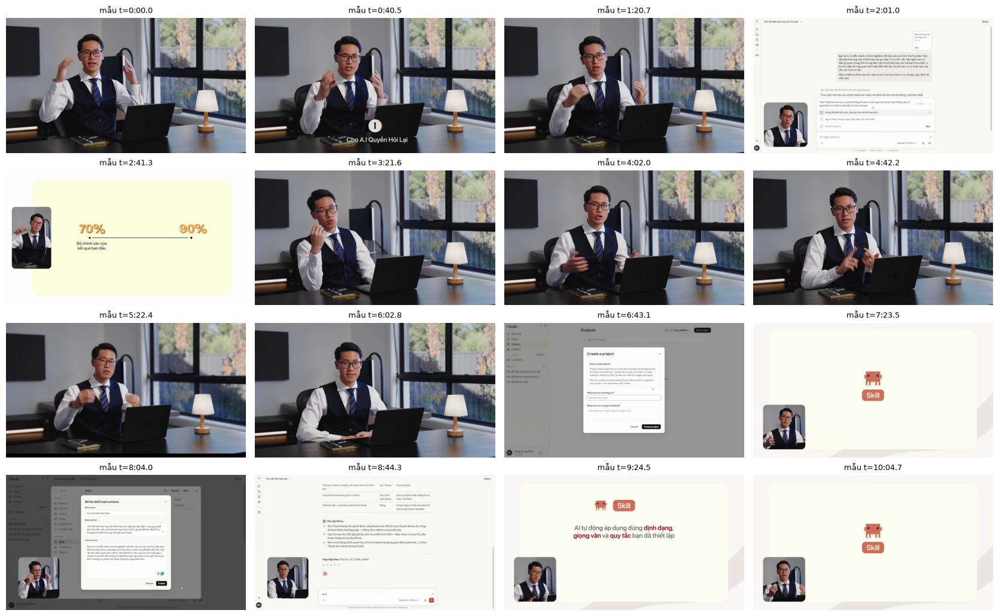

In [4]:
records, samples = [], []
started = time.monotonic()
for sample in d.scan_frames(VIDEO, source, WORK, SAMPLE_HZ, FINE_HZ, ROI, IGNORED, skip_nonref=True, records=records):
    samples.append(sample)
print(f"{len(samples)} mẫu 1 Hz, {sum(len(s['fine']) for s in samples)} khung 8 Hz, {time.monotonic() - started:.1f} s")
table(([{"t": round(s["time_sec"], 2), "độ nét": round(s["sharpness"], 1),
                       "số khung 8 Hz trước đó": len(s["fine"]), "ảnh": s["image_path"]} for s in samples[:12]]))
step = max(1, len(samples) // 16)
picks = samples[::step][:16]
grid([Image.open(WORK / s["image_path"]) for s in picks], [f"mẫu t={clock(s['time_sec'])}" for s in picks])

## Bước 3 — "Chữ ký" của một khung hình

Mỗi khung được thu về 240×135, gồm 2 kênh: **ảnh xám làm mờ** (bắt đổi màu, đổi nền) và **đường biên Canny**
(bắt chữ mới trên nền trắng giống nhau). Khoảng cách giữa hai chữ ký là max của hai kênh; kênh xám bỏ 3% điểm
thay đổi nhiều nhất để không bị con trỏ chuột làm nhiễu.

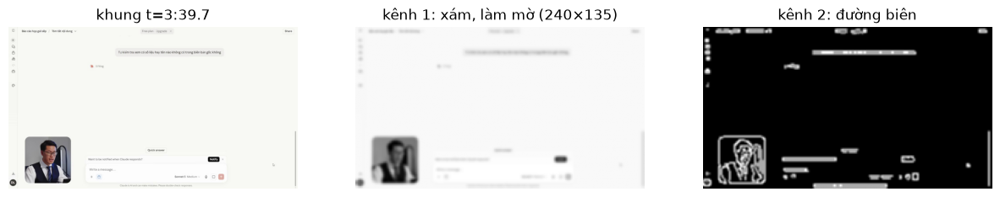

In [5]:
example = samples[len(samples) // 3]
fig, axes = plt.subplots(1, 3, figsize=(15, 3.2))
axes[0].imshow(Image.open(WORK / example["image_path"])); axes[0].set_title(f"khung t={clock(example['time_sec'])}")
axes[1].imshow(example["signature"][0], cmap="gray"); axes[1].set_title("kênh 1: xám, làm mờ (240×135)")
axes[2].imshow(example["signature"][1], cmap="gray"); axes[2].set_title("kênh 2: đường biên")
for ax in axes: ax.axis("off")
plt.show()

## Bước 4 — Khoảng cách giữa các mẫu liên tiếp

Đỉnh cao là lúc hình thay đổi. Đường đỏ là ngưỡng **0.055**: vượt ngưỡng mới được xét là ranh giới.

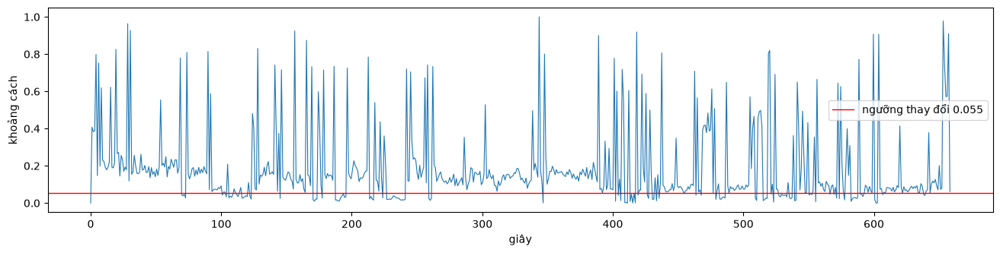

516 / 654 bước vượt ngưỡng


In [6]:
times = np.array([s["time_sec"] for s in samples])
steps = np.array([0.0] + [d.signature_distance(a["signature"], b["signature"]) for a, b in zip(samples, samples[1:])])
fig, ax = plt.subplots(figsize=(16, 3.5))
ax.plot(times, steps, lw=0.8); ax.axhline(CHANGE, color="red", lw=1, label="ngưỡng thay đổi 0.055")
ax.set_xlabel("giây"); ax.set_ylabel("khoảng cách"); ax.legend(); plt.show()
print(f"{(steps >= CHANGE).sum()} / {len(steps)} bước vượt ngưỡng")

## Bước 5 — Tìm ranh giới ổn định

Một ranh giới được **chấp nhận** khi:

1. mẫu mới khác **trạng thái tham chiếu** ≥ 0.055;
2. mẫu kế tiếp giống mẫu mới (≤ 0.035), tức hình đã **đứng yên** ở trạng thái mới trong 2 mẫu;
3. cách ranh giới trước ≥ 2 giây.

Nhờ vậy, chuyển cảnh mờ dần hay video đang chạy sẽ không sinh ra hàng loạt ranh giới.

35 ranh giới ổn định


#,thời điểm (1 Hz),khác tham chiếu
0,1:11.7,0.812
1,1:42.9,0.575
2,1:44.9,0.216
3,1:55.9,0.057
4,2:02.0,0.122
5,2:24.1,0.457
6,2:49.4,0.079
7,2:56.4,0.413
8,3:32.7,0.461
9,3:42.8,0.465


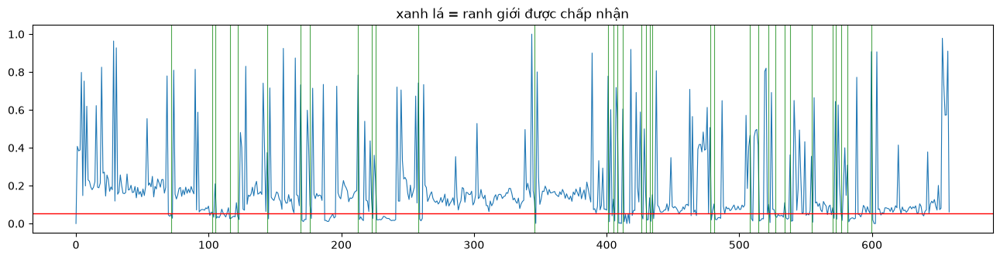

In [7]:
stable_bounds, candidates, _ = d.detect_stable_boundaries(
    iter(samples), source["duration_sec"], CHANGE, STABLE, STABLE_SAMPLES, MIN_INTERVAL)
print(f"{len(candidates)} ranh giới ổn định")
table(([{"#": i, "thời điểm (1 Hz)": clock(c["time_sec"]),
                       "khác tham chiếu": round(d.signature_distance(c["old_signature"], c["signature"]), 3)}
                      for i, c in enumerate(candidates)]))
fig, ax = plt.subplots(figsize=(16, 3.5))
ax.plot(times, steps, lw=0.8)
for c in candidates:
    ax.axvline(c["time_sec"], color="green", lw=0.8, alpha=0.7)
ax.axhline(CHANGE, color="red", lw=1); ax.set_title("xanh lá = ranh giới được chấp nhận"); plt.show()

## Bước 6 — Tinh chỉnh ranh giới bằng khung 8 Hz

Mẫu 1 Hz có thể trễ tới 1 giây. Trong các khung 8 Hz ngay trước ranh giới, chọn khung **sớm nhất** đã khác
trạng thái cũ và đã giống trạng thái mới.

In [8]:
refined = [0.0]
rows = []
for c in candidates:
    better = d.refine_from_buffer(c, CHANGE, STABLE)
    refined.append(max(refined[-1] + MIN_INTERVAL, min(better, c["time_sec"])))
    rows.append({"1 Hz": round(c["time_sec"], 2), "sau tinh chỉnh": round(refined[-1], 2),
                 "sớm hơn (s)": round(c["time_sec"] - refined[-1], 2)})
boundaries = refined + [source["duration_sec"]]
table((rows))

1 Hz,sau tinh chỉnh,sớm hơn (s)
71.7,70.95,0.75
102.89,102.89,0.0
104.9,104.89,0.0
115.95,115.57,0.38
121.96,121.33,0.63
144.14,143.77,0.38
169.38,168.5,0.88
176.43,175.63,0.79
212.67,212.42,0.25
222.76,222.26,0.5


## Bước 7 — Mặt nạ chuyển động

Điểm ảnh **thay đổi trong hơn 30% số giây** của video (giảng viên cử động, nền động) bị coi là "vùng bận".
Chạy lại bước 5 với vùng bận bị che để bắt những slide chỉ đổi ở phần còn lại. Ranh giới mới chỉ được thêm
nếu cách mọi ranh giới cũ ≥ 2 giây.

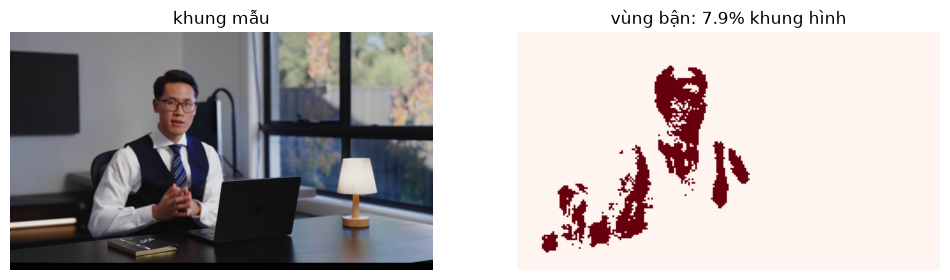

Ranh giới thêm nhờ mặt nạ: ['1:39.9', '1:58.0', '3:34.7', '5:10.3', '6:31.1', '6:58.3', '7:19.5', '7:33.7', '7:42.7', '7:44.7', '8:08.1', '9:21.5', '9:48.6', '10:05.7', '10:21.0', '10:42.1']


In [9]:
mask = d.motion_mask(records)
if mask is None:
    print("Không có vùng bận rõ ràng (0% hoặc > 85% khung hình): bỏ qua bước này.")
    masked_extra = []
else:
    masked = d.masked_boundaries(records, source["duration_sec"], mask, CHANGE, STABLE, STABLE_SAMPLES, MIN_INTERVAL)
    merged = d.union_boundaries(boundaries, masked, MIN_INTERVAL)
    masked_extra = sorted(set(merged) - set(boundaries))
    boundaries = merged
    fig, axes = plt.subplots(1, 2, figsize=(12, 3.4))
    axes[0].imshow(Image.open(WORK / samples[len(samples) // 2]["image_path"])); axes[0].set_title("khung mẫu")
    axes[1].imshow(mask, cmap="Reds"); axes[1].set_title(f"vùng bận: {mask.mean():.1%} khung hình")
    for ax in axes: ax.axis("off")
    plt.show()
print("Ranh giới thêm nhờ mặt nạ:", [clock(t) for t in masked_extra] or "không có")

## Bước 8 — Tách thay đổi "ẩn"

Bước 5 cần hình đứng yên sau khi đổi, nên bỏ lỡ hai trường hợp:

- **tĩnh → động**: slide đứng yên rồi chuyển sang đoạn phim chạy liên tục (quảng cáo, cảnh quay);
- **động → lắng lại**: đoạn phim chạy rồi dừng ở một cảnh chỉ nhúc nhích nhẹ.

Mỗi đoạn giữa hai ranh giới được kiểm tra hai trường hợp này.

In [10]:
checked, hidden = [boundaries[0]], []
for start, end in zip(boundaries, boundaries[1:]):
    splits = d.hidden_change_splits(records, start, end, CHANGE, STABLE, MIN_INTERVAL)
    hidden += splits
    checked += splits + [end]
boundaries = checked
print("Ranh giới thêm ở bước này:", [clock(t) for t in hidden] or "không có")
print(f"Tổng cộng {len(boundaries) - 1} trạng thái hình ảnh")

Ranh giới thêm ở bước này: ['1:08.7', '1:13.7', '1:31.9', '2:04.0', '4:02.0', '5:47.7', '7:00.3', '7:02.3', '7:16.5', '7:48.8', '8:31.2', '8:39.2', '8:44.3', '9:09.4', '9:16.4', '9:38.6', '10:17.9']
Tổng cộng 69 trạng thái hình ảnh


## Bước 9 — Ảnh nét nhất cho mỗi trạng thái

Trong mỗi trạng thái, chọn mẫu có **độ nét (phương sai Laplacian) cao nhất**, ưu tiên mẫu không sát hai đầu đoạn.

state,start,end,dài (s),keyframe,độ nét
0,0.0,68.65,68.7,25.36,901.9
1,68.65,70.95,2.3,69.65,519.3
2,70.95,73.7,2.8,71.7,514.1
3,73.7,91.88,18.2,89.88,527.9
4,91.88,99.89,8.0,98.89,401.6
5,99.89,102.89,3.0,101.89,437.3
6,102.89,104.89,2.0,103.9,433.6
7,104.89,115.57,10.7,113.91,470.1
8,115.57,117.95,2.4,116.95,456.2
9,117.95,121.33,3.4,119.95,456.7


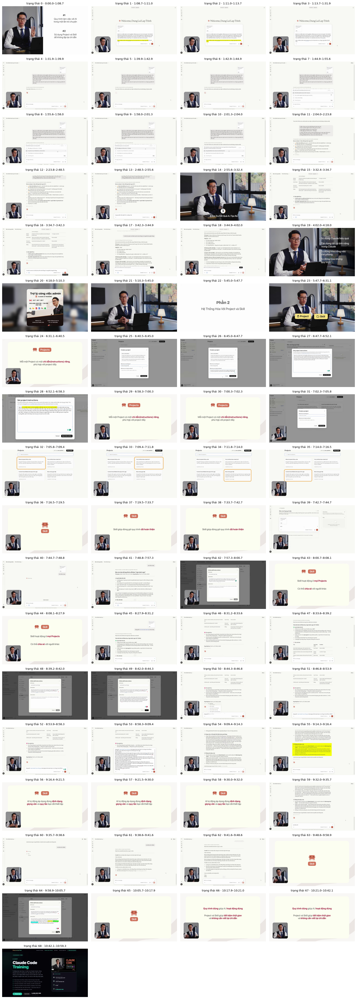

In [11]:
states, views = [], []
for index, (start, end) in enumerate(zip(boundaries, boundaries[1:])):
    pick = d.pick_scanned_keyframe(records, start, end)
    if pick is not None:
        image = Image.open(WORK / pick["image_path"]).convert("RGB")
        at, sharp = pick["time_sec"], pick["sharpness"]
    else:
        image, at, sharp = d.select_keyframe(VIDEO, source, start, end)
    states.append({"state": index, "start": round(start, 2), "end": round(end, 2), "dài (s)": round(end - start, 1),
                   "keyframe": round(at, 2), "độ nét": round(sharp, 1), "image": image})
    views.append(d.reveal_view(image, ROI, IGNORED))
table(([{k: v for k, v in s.items() if k != "image"} for s in states]))
grid([s["image"] for s in states], [f"trạng thái {s['state']} · {clock(s['start'])}–{clock(s['end'])}" for s in states])

## Bước 10 — Gộp slide hiện dần

So từng trạng thái với trạng thái trước đó (chỉ xét **nét chữ và hình vẽ**; phần có mặt ở hầu hết các trạng thái như
logo, khung tiêu đề bị bỏ qua). **Gộp** khi cả ba điều kiện đúng:

- nội dung cũ còn giữ ≥ **85%** (`content_retained`);
- ảnh thay đổi ≤ **25%** (`image_change`);
- nội dung mới ≥ 0.9 lần nội dung cũ (`content_growth`).

Ngoài ra, trạng thái mới còn phải giữ ≥ 60% nội dung của trạng thái **đầu nhóm** (`anchor_retained`), để các lần
gộp không nối dây sang một slide khác.

trước,sau,quyết định,content_retained,image_change,content_growth,old_content_pixels
0,1,tách: nội dung đổi,0.0924,0.4928,0.4062,11333
1,2,GỘP (hiện thêm),0.9889,0.0071,1.0035,4603
2,3,GỘP (hiện thêm),0.9411,0.0178,1.0214,4619
3,4,tách: nội dung đổi,0.4555,0.0701,0.9339,4718
4,5,GỘP (hiện thêm),0.9251,0.0164,1.0558,4406
5,6,GỘP (hiện thêm),0.9291,0.014,0.9807,4652
6,7,GỘP (hiện thêm),0.8595,0.0321,1.1348,4562
7,8,GỘP (hiện thêm),0.8884,0.0215,0.9693,5177
8,9,GỘP (hiện thêm),0.9558,0.0132,1.0195,5018
9,10,GỘP (hiện thêm),0.8841,0.0291,1.1218,5116


Counter({'tách: nội dung đổi': 45, 'GỘP (hiện thêm)': 23})


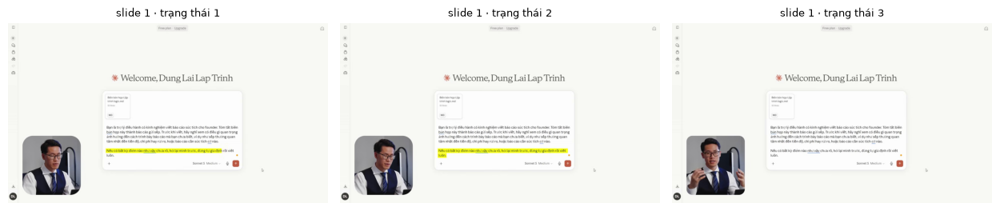

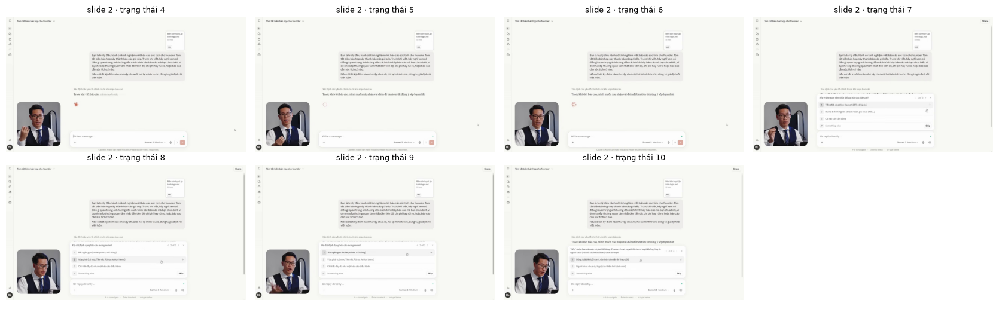

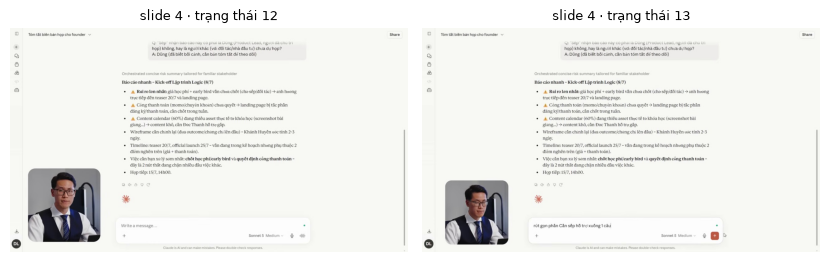

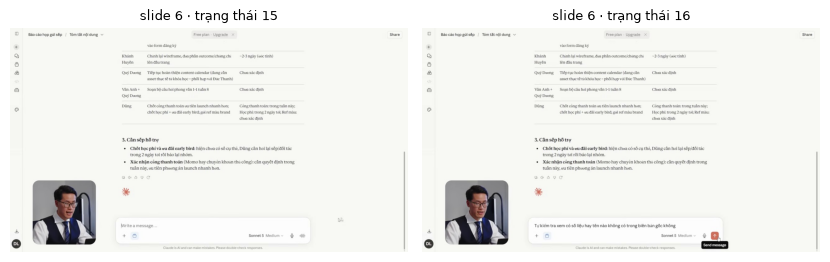

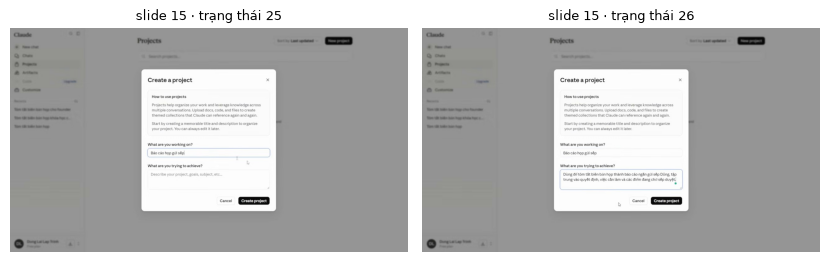

...

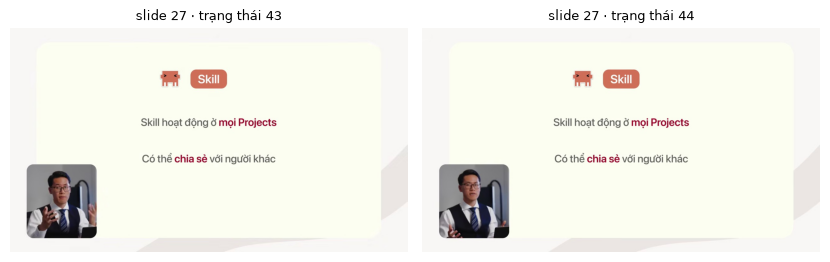

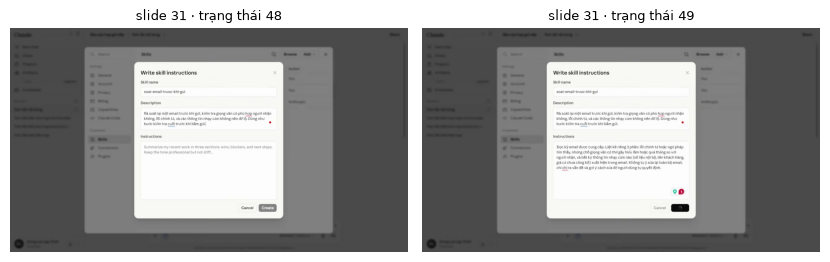

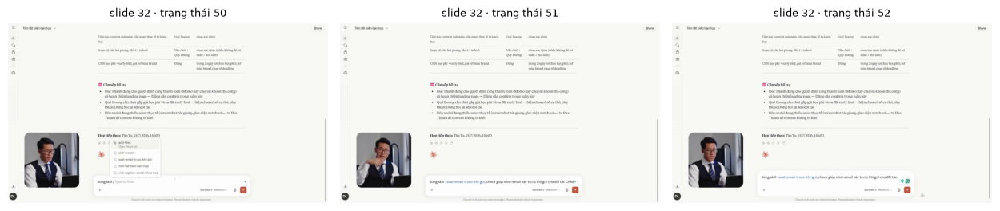

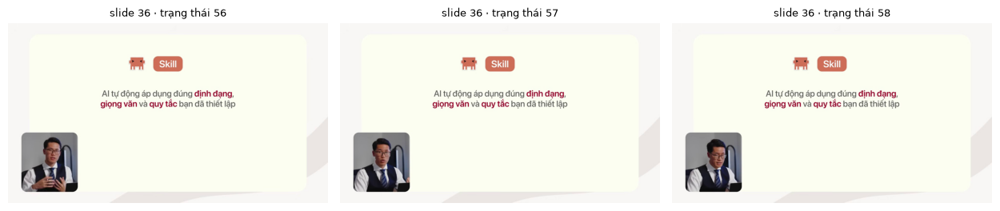

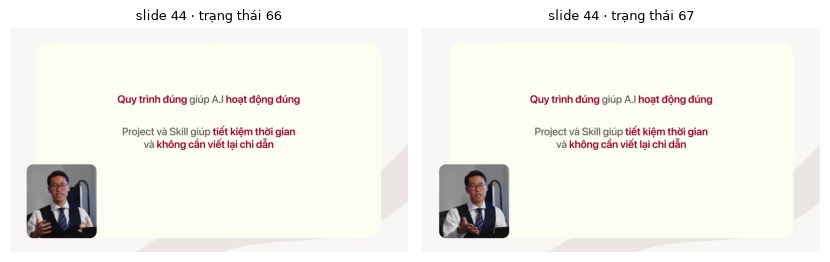

In [12]:
groups, audit = d.group_reveal_states(views)
names = {"merge_content_kept": "GỘP (hiện thêm)", "split_content_changed": "tách: nội dung đổi",
         "split_little_content": "tách: slide cũ gần như trống", "split_anchor_lost": "tách: mất nội dung đầu nhóm"}
from collections import Counter
rows = [{"trước": a["previous_state"], "sau": a["current_state"], "quyết định": names.get(a["decision"], a["decision"]),
         **{k: a[k] for k in ("content_retained", "image_change", "content_growth", "anchor_retained", "old_content_pixels") if k in a}}
        for a in audit]
table(rows)
print(Counter(r["quyết định"] for r in rows))
for number, group in enumerate(groups):
    if len(group) > 1:
        grid([states[i]["image"] for i in group], [f"slide {number} · trạng thái {i}" for i in group], columns=min(4, len(group)))

## Bước 11 — Kết quả cuối: danh sách slide

Mỗi nhóm là một slide. Ảnh đại diện là **trạng thái cuối** của nhóm, tức lúc slide đã hiện đầy đủ nhất.

69 trạng thái → 46 slide


slide,start,end,số trạng thái
0,0:00.0,1:08.7,1
1,1:08.7,1:31.9,3
2,1:31.9,2:04.0,7
3,2:04.0,2:23.8,1
4,2:23.8,2:55.6,2
5,2:55.6,3:32.4,1
6,3:32.4,3:42.3,2
7,3:42.3,3:44.9,1
8,3:44.9,4:02.0,1
9,4:02.0,4:18.0,1


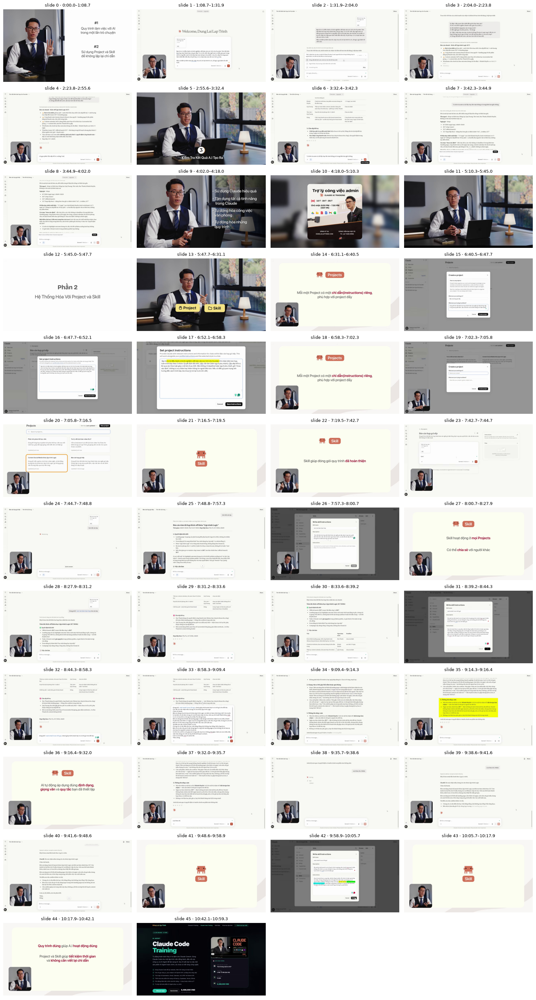

In [13]:
slides = [{"slide": n, "start": clock(states[g[0]]["start"]), "end": clock(states[g[-1]]["end"]),
           "số trạng thái": len(g), "image": states[g[-1]]["image"]} for n, g in enumerate(groups)]
print(f"{len(states)} trạng thái → {len(slides)} slide")
table(([{k: v for k, v in s.items() if k != "image"} for s in slides]))
grid([s["image"] for s in slides], [f"slide {s['slide']} · {s['start']}–{s['end']}" for s in slides])

## Bước 12 — Kiểm chứng với hàm của pipeline

Chạy `run_slide_detection` (hàm pipeline gọi thật, cùng tham số) và so sánh ranh giới từng slide với kết quả
từng bước ở trên.

In [14]:
shutil.rmtree(WORK / "_scan", ignore_errors=True)
started = time.monotonic()
_, manifest, intervals = d.run_slide_detection(VIDEO, WORK / "pipeline", VIDEO_ID)
print(f"Pipeline: {manifest['visual_state_count']} trạng thái, {len(intervals)} slide, {time.monotonic() - started:.0f} s")
ours = [(round(states[g[0]]["start"], 2), round(states[g[-1]]["end"], 2)) for g in groups]
theirs = [(round(i["start_sec"], 2), round(i["end_sec"], 2)) for i in intervals]
print("Trùng khớp hoàn toàn:", ours == theirs)
if ours != theirs:
    table([{"từng bước": a, "pipeline": b} for a, b in zip(ours, theirs)])

Keyframe 1/69: 0.00s


Keyframe 21/69: 257.97s


Keyframe 41/69: 464.71s


Keyframe 61/69: 575.70s


Hoàn tất 01_slides: C:\Users\nguye\OneDrive\Máy tính\Thesis\kaggle\lecture_rag\runs\explain_YT_vk93aEGb9Bo\pipeline\01_slides
Pipeline: 69 trạng thái, 46 slide, 22 s
Trùng khớp hoàn toàn: True
